In [56]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import joblib

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# EDA - Análise Exploratória dos Dados

In [57]:
sheet_url = 'https://docs.google.com/spreadsheets/d/1ZE7GSbI6BzqY9SP9huCoSxP29NLxxb7s/edit?gid=70563490#gid=70563490'

csv_url = 'https://docs.google.com/spreadsheets/d/1ZE7GSbI6BzqY9SP9huCoSxP29NLxxb7s/export?format=csv&gid=70563490'

df = pd.read_csv(csv_url)
display(df.head())

,EstadoCivil,Curso,QualificacaoAnterior,QualificacaoAnteriorGrau,Nacionalidade,NotaAdmissao,NecessidadesEspeciais,Devedor,MensalidadesEmDia,Genero,...,UnidadesCurriculares2SemestreCreditado,UnidadesCurriculares2SemestreInscrito,UnidadesCurriculares2SemestreAvaliacoes,UnidadesCurriculares2SemestreAprovado,UnidadesCurriculares2SemestreGrau,UnidadesCurriculares2SemestreSemAvaliacoes,TaxaDesemprego,TaxaInflacao,PIB,Target
0,Solteiro,Design de Animação e Multimédia,Ensino Secundário,122,Português,"127,3",0,0,1,Masculino,...,0,0,0,0,0,0,"10,8","1,4","1,74",Desistente
1,Solteiro,Turismo,Ensino Secundário,160,Português,"142,5",0,0,0,Masculino,...,0,6,6,6,"1,36667E+16",0,"13,9","-0,3","0,79",Graduado
2,Solteiro,Design de Comunicação,Ensino Secundário,122,Português,"124,8",0,0,0,Masculino,...,0,6,0,0,0,0,"10,8","1,4","1,74",Desistente
3,Solteiro,Jornalismo e Comunicação,Ensino Secundário,122,Português,"119,6",0,0,1,Feminino,...,0,6,10,5,"12,4",0,"9,4","-0,8","-3,12",Graduado
4,Casado,Serviço Social (prestação nocturna),Ensino Secundário,100,Português,"141,5",0,0,1,Feminino,...,0,6,6,6,13,0,"13,9","-0,3","0,79",Graduado


In [58]:
df.shape

(4424, 28)

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 28 columns):
 #   Column                                      Non-Null Count  Dtype 
---  ------                                      --------------  ----- 
 0   EstadoCivil                                 4424 non-null   object
 1   Curso                                       4424 non-null   object
 2   QualificacaoAnterior                        4424 non-null   object
 3   QualificacaoAnteriorGrau                    4424 non-null   object
 4   Nacionalidade                               4424 non-null   object
 5   NotaAdmissao                                4424 non-null   object
 6   NecessidadesEspeciais                       4424 non-null   int64 
 7   Devedor                                     4424 non-null   int64 
 8   MensalidadesEmDia                           4424 non-null   int64 
 9   Genero                                      4424 non-null   object
 10  Bolsista                

In [60]:
df.isna().sum()

,0
EstadoCivil,0
Curso,0
QualificacaoAnterior,0
QualificacaoAnteriorGrau,0
Nacionalidade,0
NotaAdmissao,0
NecessidadesEspeciais,0
Devedor,0
MensalidadesEmDia,0
Genero,0


In [61]:
df.duplicated().sum()

np.int64(1)

In [62]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
NecessidadesEspeciais,4424.0,0.011528,0.106760,0.0,0.0,0.0,0.0,1.0
Devedor,4424.0,0.113698,0.317480,0.0,0.0,0.0,0.0,1.0
MensalidadesEmDia,4424.0,0.880651,0.324235,0.0,1.0,1.0,1.0,1.0
Bolsista,4424.0,0.248418,0.432144,0.0,0.0,0.0,0.0,1.0
International,4424.0,0.024864,0.155729,0.0,0.0,0.0,0.0,1.0
UnidadesCurriculares1SemestreCreditado,4424.0,0.709991,2.360507,0.0,0.0,0.0,0.0,20.0
UnidadesCurriculares1SemestreInscrito,4424.0,6.270570,2.480178,0.0,5.0,6.0,7.0,26.0
UnidadesCurriculares1SemestreAvaliacoes,4424.0,8.299051,4.179106,0.0,6.0,8.0,10.0,45.0
UnidadesCurriculares1SemestreAprovado,4424.0,4.706600,3.094238,0.0,3.0,5.0,6.0,26.0
UnidadesCurriculares1SemestreSemAvaliacoes,4424.0,0.137658,0.690880,0.0,0.0,0.0,0.0,12.0


In [63]:
df.columns

Index(['EstadoCivil', 'Curso', 'QualificacaoAnterior',
       'QualificacaoAnteriorGrau', 'Nacionalidade', 'NotaAdmissao',
       'NecessidadesEspeciais', 'Devedor', 'MensalidadesEmDia', 'Genero',
       'Bolsista', 'International', 'UnidadesCurriculares1SemestreCreditado',
       'UnidadesCurriculares1SemestreInscrito',
       'UnidadesCurriculares1SemestreAvaliacoes',
       'UnidadesCurriculares1SemestreAprovado',
       'UnidadesCurriculares1SemestreGrau',
       'UnidadesCurriculares1SemestreSemAvaliacoes',
       'UnidadesCurriculares2SemestreCreditado',
       'UnidadesCurriculares2SemestreInscrito',
       'UnidadesCurriculares2SemestreAvaliacoes',
       'UnidadesCurriculares2SemestreAprovado',
       'UnidadesCurriculares2SemestreGrau',
       'UnidadesCurriculares2SemestreSemAvaliacoes', 'TaxaDesemprego',
       'TaxaInflacao', 'PIB', 'Target'],
      dtype='object')

<Axes: xlabel='Target'>

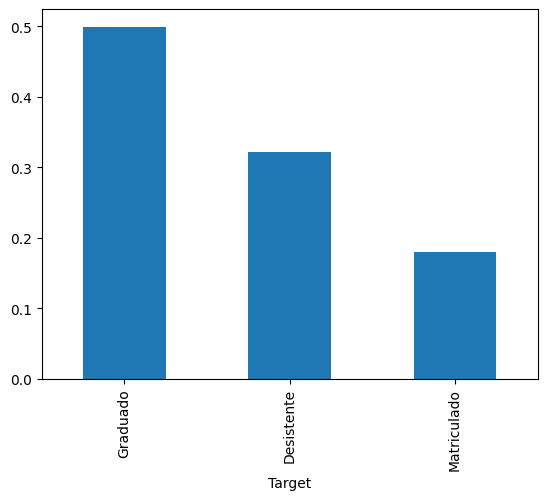

In [64]:
df["Target"].value_counts(normalize=True).plot(kind="bar")

In [65]:
df["Target"].value_counts()

,count
Target,
Graduado,2209
Desistente,1421
Matriculado,794


### Isolando os dados para trabalhar apenas com `Graduado`e `Desistente`. `Matriculado` é um cenário desconhecido para trabalhar com previsão e realizar as análises

In [66]:
df_modelo = df[df["Target"].isin(["Graduado", "Desistente"])].copy()
df_modelo["evasao"] = (df_modelo["Target"] == "Desistente").astype(int)
df_modelo = df_modelo.drop(columns=["Target"])

df_modelo["evasao"].value_counts(normalize=True)

,proportion
evasao,
0,0.60854
1,0.39146


In [67]:
df_modelo.sample(5)

,EstadoCivil,Curso,QualificacaoAnterior,QualificacaoAnteriorGrau,Nacionalidade,NotaAdmissao,NecessidadesEspeciais,Devedor,MensalidadesEmDia,Genero,...,UnidadesCurriculares2SemestreCreditado,UnidadesCurriculares2SemestreInscrito,UnidadesCurriculares2SemestreAvaliacoes,UnidadesCurriculares2SemestreAprovado,UnidadesCurriculares2SemestreGrau,UnidadesCurriculares2SemestreSemAvaliacoes,TaxaDesemprego,TaxaInflacao,PIB,evasao
4355,Solteiro,Enfermagem Veterinária,Ensino Secundário,160,Português,"162,1",0,0,1,Feminino,...,0,5,9,5,"1,42857E+16",1,"9,4","-0,8","-3,12",0
1645,Solteiro,Design de Animação e Multimédia,Ensino Secundário,120,Português,"119,7",0,0,1,Feminino,...,0,0,0,0,0,0,"8,9","1,4","3,51",1
4109,Solteiro,Serviço Social,Ensino Secundário,134,Português,126,0,0,1,Feminino,...,0,6,8,5,"11,2",0,"10,8","1,4","1,74",0
1041,Solteiro,Enfermagem,Ensino Secundário,124,Português,"117,8",0,0,1,Feminino,...,0,8,8,7,"1,27914E+16",1,"10,8","1,4","1,74",0
1062,Solteiro,Serviço Social (prestação nocturna),Ensino Secundário,130,Português,"131,5",0,0,1,Feminino,...,0,6,7,6,"1,11667E+16",0,"11,1","0,6","2,02",0


In [68]:
df_modelo['EstadoCivil'].value_counts()

,count
EstadoCivil,
Solteiro,3199
Casado,327
Divorciado,75
União de Fato,22
Separado Judicialmente,5
Viúvo,2


In [69]:
df_modelo['Nacionalidade'].value_counts()

,count
Nacionalidade,
Português,3544
Brasileiro,32
Cabo-verdiano,12
Santomense,9
Espanhol,8
Guineense,5
Italiano,3
Ucraniano,3
Alemão,2


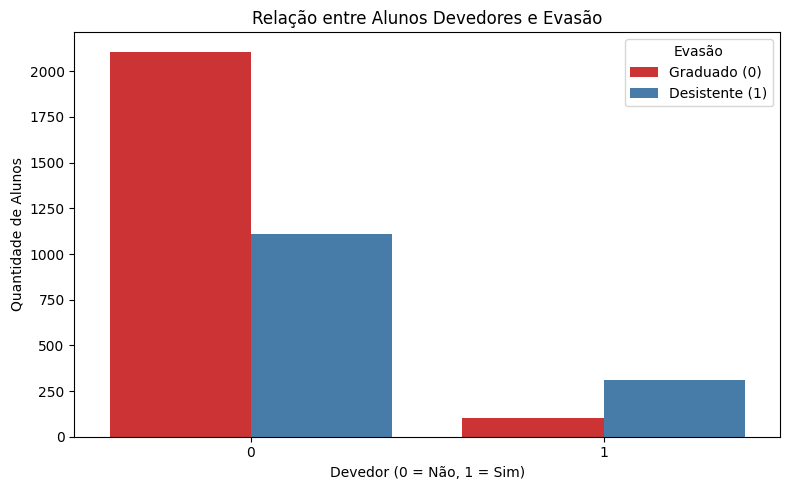

--- Proporção de Evasão entre Devedores e Não Devedores ---


evasao,0,1
Devedor,,
0,65.53,34.47
1,24.46,75.54


In [70]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_modelo, x='Devedor', hue='evasao', palette='Set1')
plt.title('Relação entre Alunos Devedores e Evasão')
plt.xlabel('Devedor (0 = Não, 1 = Sim)')
plt.ylabel('Quantidade de Alunos')
plt.legend(title='Evasão', labels=['Graduado (0)', 'Desistente (1)'])
plt.tight_layout()
plt.show()

print("--- Proporção de Evasão entre Devedores e Não Devedores ---")
tabela_devedor = pd.crosstab(df_modelo['Devedor'], df_modelo['evasao'], normalize='index') * 100
display(tabela_devedor.round(2))

## Análise Estado Civil - Target

In [71]:
# Tabela de contigencia
relation_table = pd.crosstab(df_modelo['EstadoCivil'], df_modelo['evasao'])
print("--- Tabela de Contingencia (Valori Assoluti) ---")
display(relation_table)

relation_pct = pd.crosstab(df_modelo['EstadoCivil'], df_modelo['evasao'], normalize='index') * 100
print("\n--- Tabella di Contingenza (Percentuali per riga %) ---")
display(relation_pct.round(2))

--- Tabela de Contingencia (Valori Assoluti) ---


evasao,0,1
EstadoCivil,,
Casado,148,179
Divorciado,33,42
Separado Judicialmente,1,4
Solteiro,2015,1184
União de Fato,11,11
Viúvo,1,1



--- Tabella di Contingenza (Percentuali per riga %) ---


evasao,0,1
EstadoCivil,,
Casado,45.26,54.74
Divorciado,44.00,56.00
Separado Judicialmente,20.00,80.00
Solteiro,62.99,37.01
União de Fato,50.00,50.00
Viúvo,50.00,50.00


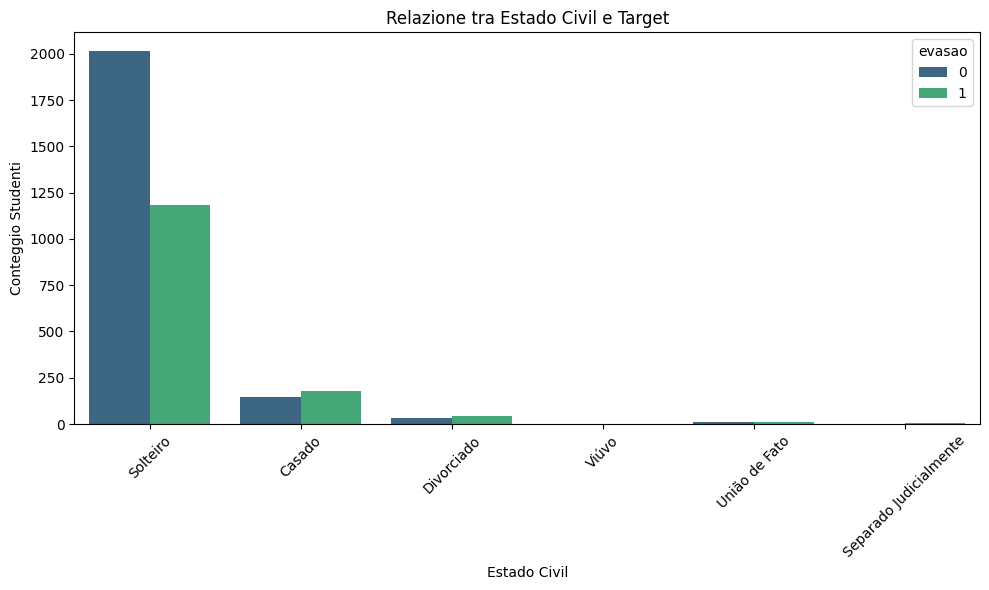

In [72]:
# Visualizaçao Grafica
plt.figure(figsize=(10, 6))
sns.countplot(data=df_modelo, x='EstadoCivil', hue='evasao', palette='viridis')
plt.title('Relazione tra Estado Civil e Target')
plt.xlabel('Estado Civil')
plt.ylabel('Conteggio Studenti')
plt.xticks(rotation=45)
plt.legend(title='evasao')
plt.tight_layout()
plt.show()

In [73]:
df_analise = df_modelo.copy()

# Função para converter colunas numéricas que possam estar com formato de string/vírgula
def limpar_coluna_numerica(coluna):
    if df_analise[coluna].dtype == 'object':
        return df_analise[coluna].astype(str).str.replace(',', '.').astype(float)
    return df_analise[coluna]

## Análise Financeiro - Target

In [74]:
df_analise['TaxaDesemprego'] = limpar_coluna_numerica('TaxaDesemprego')
df_analise['PIB'] = limpar_coluna_numerica('PIB')

In [75]:
# Análise Estatística Agrupada por Target
analise_economica = df_analise.groupby('evasao')[['TaxaDesemprego', 'PIB']].mean().reset_index()
print("--- Médias dos Indicadores Econômicos por Evasao ---")
display(analise_economica)

--- Médias dos Indicadores Econômicos por Evasao ---


,evasao,TaxaDesemprego,PIB
0,0,11.639339,0.081833
1,1,11.616397,-0.150859


/tmp/ipykernel_497/2869500990.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=df_analise, x='evasao', y='TaxaDesemprego', palette='Set2')


Text(0, 0.5, 'Taxa de Desemprego (%)')

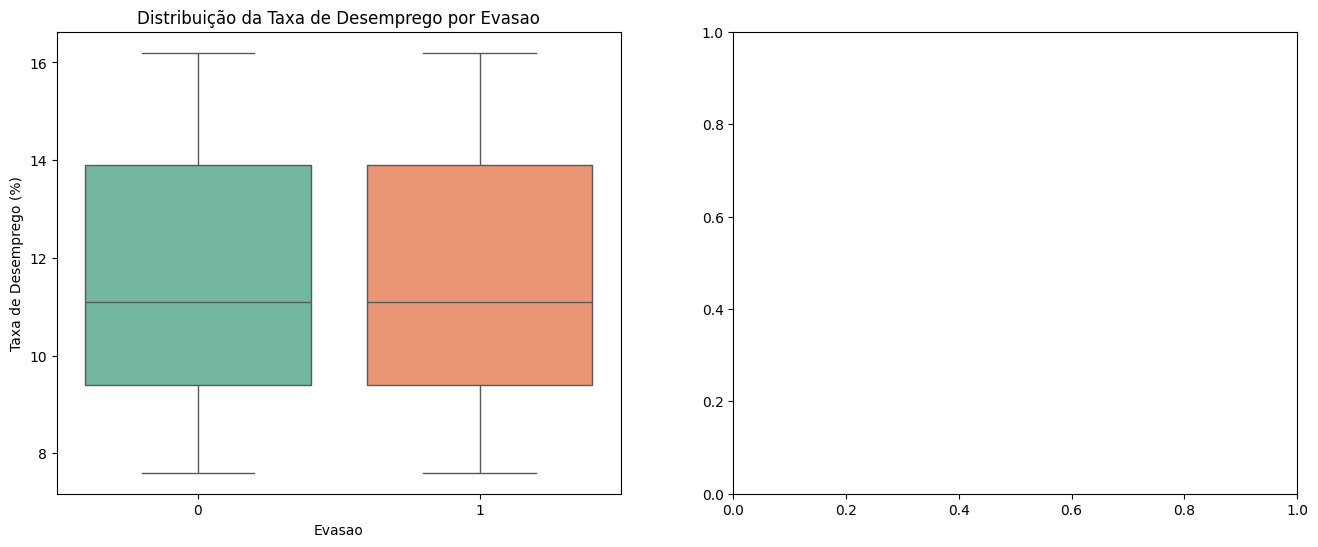

In [76]:
# Visualização com Boxplots para ver a distribuição completa
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Taxa de Desemprego
sns.boxplot(ax=axes[0], data=df_analise, x='evasao', y='TaxaDesemprego', palette='Set2')
axes[0].set_title('Distribuição da Taxa de Desemprego por Evasao')
axes[0].set_xlabel('Evasao')
axes[0].set_ylabel('Taxa de Desemprego (%)')

In [77]:
# PIB
sns.boxplot(ax=axes[1], data=df_analise, x='evasao', y='PIB', palette='Set2')
axes[1].set_title('Distribuição do PIB por Evasao')
axes[1].set_xlabel('Evasao')
axes[1].set_ylabel('PIB (Crescimento/Taxa)')

plt.tight_layout()
plt.show()

/tmp/ipykernel_497/2623832110.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=df_analise, x='evasao', y='PIB', palette='Set2')


<Figure size 640x480 with 0 Axes>

/tmp/ipykernel_497/2882617068.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analise, x='evasao', y='TaxaDesemprego', palette='Set2')


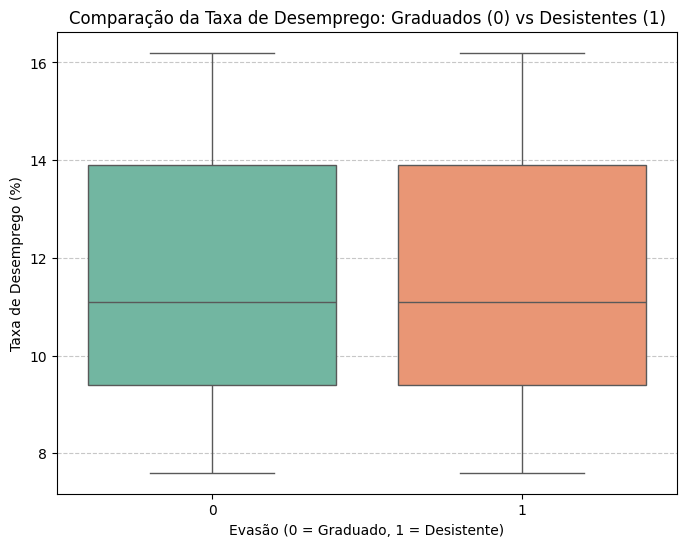

In [78]:
# boxplot específico para comparar a Taxa de Desemprego entre os grupos de evasão
plt.figure(figsize=(8, 6))
sns.boxplot(data=df_analise, x='evasao', y='TaxaDesemprego', palette='Set2')
plt.title('Comparação da Taxa de Desemprego: Graduados (0) vs Desistentes (1)')
plt.xlabel('Evasão (0 = Graduado, 1 = Desistente)')
plt.ylabel('Taxa de Desemprego (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

--- Matriz de Correlação (Devedor, TaxaDesemprego, Evasao) ---


,Devedor,TaxaDesemprego,evasao
Devedor,1.000000,0.042792,0.267207
TaxaDesemprego,0.042792,1.000000,-0.004198
evasao,0.267207,-0.004198,1.000000


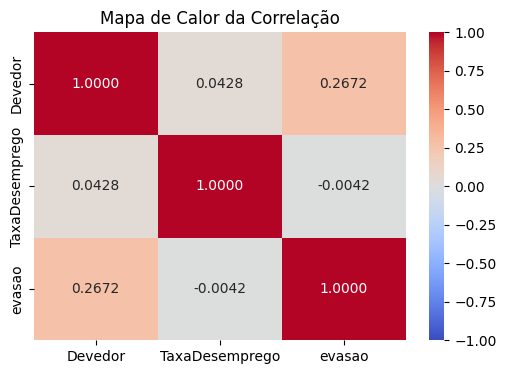

In [79]:
subset_df = df_analise[['Devedor', 'TaxaDesemprego', 'evasao']]
matrice_corr = subset_df.corr()

print("--- Matriz de Correlação (Devedor, TaxaDesemprego, Evasao) ---")
display(matrice_corr)

# Visualizzazione grafica della matrice di correlazione
plt.figure(figsize=(6, 4))
sns.heatmap(matrice_corr, annot=True, cmap='coolwarm', fmt='.4f', vmin=-1, vmax=1)
plt.title('Mapa de Calor da Correlação')
plt.show()

--- Correlazione di tutte le variabili con l'Evasione (evasao) ---


,evasao
evasao,1.000000
Devedor,0.267207
UnidadesCurriculares2SemestreSemAvaliacoes,0.102687
UnidadesCurriculares1SemestreSemAvaliacoes,0.074642
TaxaInflacao,0.030326
NecessidadesEspeciais,0.007254
TaxaDesemprego,-0.004198
International,-0.006181
UnidadesCurriculares1SemestreCreditado,-0.046900
PIB,-0.050260


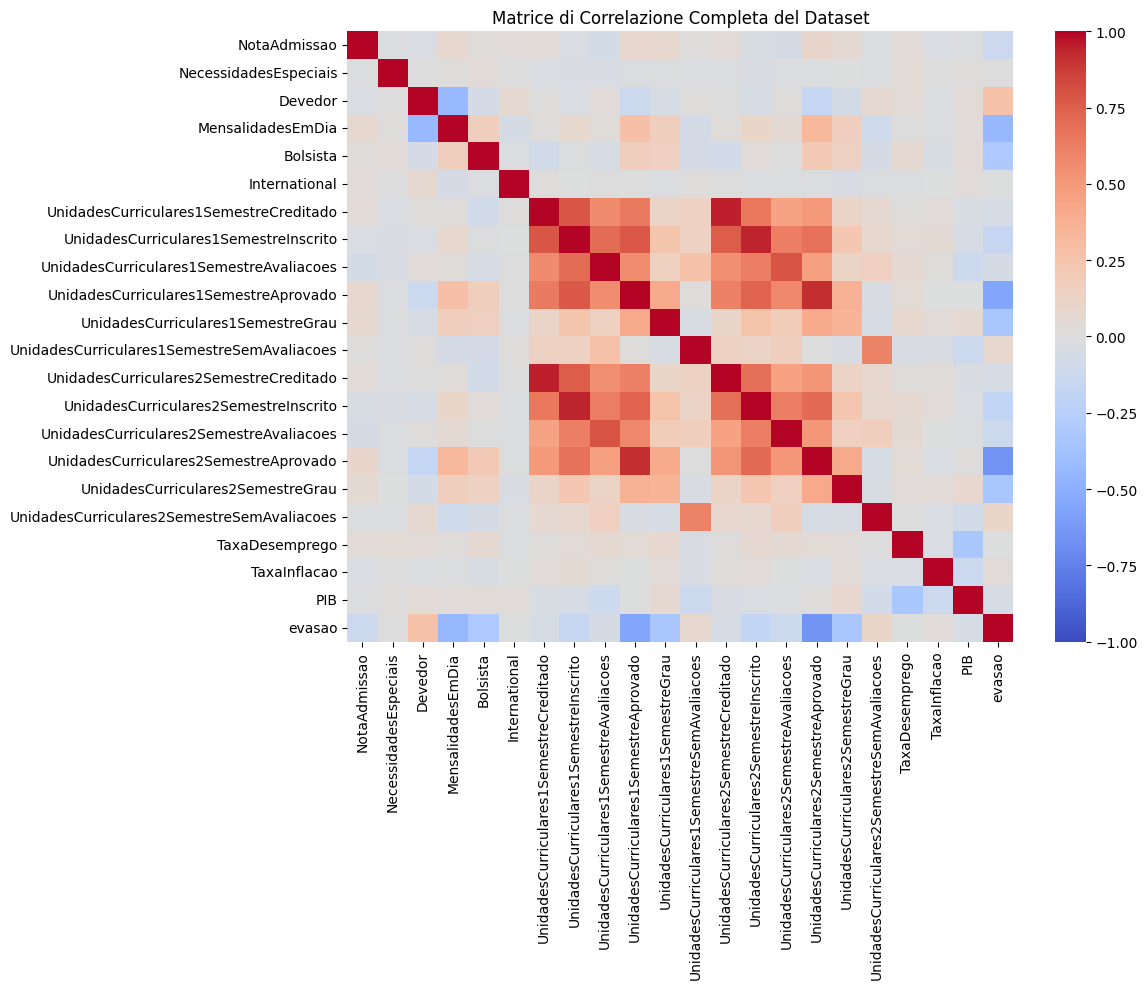

In [80]:
df_completo_corr = df_modelo.copy()

for col in ['NotaAdmissao', 'UnidadesCurriculares1SemestreGrau', 'UnidadesCurriculares2SemestreGrau', 'TaxaDesemprego', 'TaxaInflacao', 'PIB']:
    if col in df_completo_corr.columns:
        df_completo_corr[col] = df_completo_corr[col].astype(str).str.replace(',', '.').astype(float)

# colunas numericas
numerics = df_completo_corr.select_dtypes(include=[np.number])
completa_corr = numerics.corr()

# correlação com 'evasao'
evasao_corr = completa_corr['evasao'].sort_values(ascending=False).to_frame()
print("--- Correlazione di tutte le variabili con l'Evasione (evasao) ---")
display(evasao_corr)

# correlação principal
plt.figure(figsize=(12, 10))
sns.heatmap(completa_corr, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matrice di Correlazione Completa del Dataset')
plt.tight_layout()
plt.show()

In [81]:
# Filtrando e ordenando as correlações com 'evasao' pelo valor absoluto para identificar as mais fortes
corr_evasao_abs = completa_corr['evasao'].abs().sort_values(ascending=False).to_frame()
corr_evasao_abs['Coeficiente Real'] = completa_corr['evasao']
corr_evasao_abs.columns = ['Correlação Absoluta', 'Coeficiente de Correlação']

print("--- Variáveis com maior impacto/relação com a Evasão (Ordenado por Força de Correlação) ---")
display(corr_evasao_abs.head(10))

--- Variáveis com maior impacto/relação com a Evasão (Ordenado por Força de Correlação) ---


,Correlação Absoluta,Coeficiente de Correlação
evasao,1.000000,1.000000
UnidadesCurriculares2SemestreAprovado,0.653995,-0.653995
UnidadesCurriculares1SemestreAprovado,0.554881,-0.554881
MensalidadesEmDia,0.442138,-0.442138
UnidadesCurriculares1SemestreGrau,0.331331,-0.331331
UnidadesCurriculares2SemestreGrau,0.329460,-0.329460
Bolsista,0.313018,-0.313018
Devedor,0.267207,0.267207
UnidadesCurriculares2SemestreInscrito,0.182897,-0.182897
UnidadesCurriculares1SemestreInscrito,0.161074,-0.161074


### Análise das Variáveis mais Correlacionadas com a Evasão

Analisando os resultados da correlação com `evasao` (onde **1** representa o aluno Desistente/Evasão e **0** o aluno Graduado):

1. **Unidades Curriculares do 2º e 1º Semestre (Aprovadas e Notas/Grau) [Forte Correlação Negativa]**:
   * `UnidadesCurriculares2SemestreAprovado` (~ -0.65) e `UnidadesCurriculares1SemestreAprovado` (~ -0.55) possuem as correlações negativas mais expressivas.
   * *Significado prático*: Quanto mais disciplinas o aluno aprova em ambos os semestres, drasticamente menor é a chance de ele evadir. O desempenho acadêmico inicial é o preditor mais forte de sucesso.
   * O mesmo padrão se aplica às notas finais (`Grau`) de ambos os semestres.

2. **Mensalidades em Dia (MensalidadesEmDia) [Forte Correlação Negativa]**:
   * Apresenta uma correlação de aproximadamente -0.44.
   * *Significado prático*: Manter as mensalidades em dia está fortemente associado à permanência do aluno. Alunos com mensalidades atrasadas têm um risco significativamente maior de evasão.

3. **Devedor [Correlação Positiva]**:
   * Apresenta uma correlação de aproximadamente +0.27.
   * *Significado prático*: Alunos com situação de devedores ativos têm maior tendência a desistir do curso, confirmando o forte impacto do fator financeiro na decisão de permanência.

In [82]:
df['Curso'].value_counts()

,count
Curso,
Enfermagem,766
Gestão,380
Serviço Social,355
Enfermagem Veterinária,337
Jornalismo e Comunicação,331
Gestão de Publicidade e Marketing,268
Gestão (presencial noturno),268
Turismo,252
Design de Comunicação,226


In [83]:
df['Target'].value_counts()

,count
Target,
Graduado,2209
Desistente,1421
Matriculado,794


## Matriz de correlação

In [84]:
df_corr = df_analise.copy()

# Convertendo outras colunas categóricas para numéricas usando Label Encoding onde for aplicável,
# ou apenas selecionando as colunas que já são numéricas por padrão
# Garantindo que apenas colunas numéricas sejam utilizadas
numeric_df = df_corr.select_dtypes(include=[np.number])

# matriz de correlação de Pearson
correlation_matrix = numeric_df.corr()

# correlação de todas as colunas com a coluna evasao
target_correlation = correlation_matrix['evasao'].sort_values(ascending=False)

print("--- Correlação de todas as colunas com a Evasão (evasao) --- ")
print("(Valores próximos a 1 indicam forte relação com a Desistência/Evasão, e próximos a -1 com a Graduação)\n")
display(target_correlation.to_frame())

--- Correlação de todas as colunas com a Evasão (evasao) --- 
(Valores próximos a 1 indicam forte relação com a Desistência/Evasão, e próximos a -1 com a Graduação)



,evasao
evasao,1.000000
Devedor,0.267207
UnidadesCurriculares2SemestreSemAvaliacoes,0.102687
UnidadesCurriculares1SemestreSemAvaliacoes,0.074642
NecessidadesEspeciais,0.007254
TaxaDesemprego,-0.004198
International,-0.006181
UnidadesCurriculares1SemestreCreditado,-0.046900
PIB,-0.050260
UnidadesCurriculares2SemestreCreditado,-0.052402


# Feature Engineering
Vamos criar novas variáveis explicativas para capturar o comportamento de evolução acadêmica e eficiência do estudante.

In [85]:
# Taxa de Aprovação por Semestre (Eficiência)
# Evita divisão por zero caso o aluno não tenha se inscrito em nenhuma matéria
df_analise['Eficiencia_1Sem'] = (df_analise['UnidadesCurriculares1SemestreAprovado'] /
                                 df_analise['UnidadesCurriculares1SemestreInscrito'].replace(0, np.nan)).fillna(0)

df_analise['Eficiencia_2Sem'] = (df_analise['UnidadesCurriculares2SemestreAprovado'] /
                                 df_analise['UnidadesCurriculares2SemestreInscrito'].replace(0, np.nan)).fillna(0)

In [86]:
# 2. Evolução de Desempenho entre Semestres
# Diferença na eficiência (positivo significa que melhorou no 2º semestre)
df_analise['Evolucao_Eficiencia'] = df_analise['Eficiencia_2Sem'] - df_analise['Eficiencia_1Sem']

# Diferença de Notas (Grau)
# Primeiro garantimos que as colunas de notas estão tratadas como numéricas
for col in ['UnidadesCurriculares1SemestreGrau', 'UnidadesCurriculares2SemestreGrau']:
    df_analise[col] = limpar_coluna_numerica(col)

df_analise['Evolucao_Grau'] = df_analise['UnidadesCurriculares2SemestreGrau'] - df_analise['UnidadesCurriculares1SemestreGrau']

In [87]:
# 3. Aluno de Risco Financeiro Extremo (Devedor E com mensalidades atrasadas)
df_analise['Risco_Financeiro'] = ((df_analise['Devedor'] == 1) & (df_analise['MensalidadesEmDia'] == 0)).astype(int)

display(df_analise[['Eficiencia_1Sem', 'Eficiencia_2Sem', 'Evolucao_Eficiencia', 'Evolucao_Grau', 'Risco_Financeiro', 'evasao']].head())

,Eficiencia_1Sem,Eficiencia_2Sem,Evolucao_Eficiencia,Evolucao_Grau,Risco_Financeiro,evasao
0,0.000000,0.000000,0.000000,0.000000e+00,0,1
1,1.000000,1.000000,0.000000,1.366670e+16,0,0
2,0.000000,0.000000,0.000000,0.000000e+00,0,1
3,1.000000,0.833333,-0.166667,-1.342860e+16,0,0
4,0.833333,1.000000,0.166667,-1.233330e+16,0,0


## Análise Exploratória Adicional
Vamos explorar o impacto do Gênero, dos Cursos e avaliar o poder preditivo das novas variáveis criadas

/tmp/ipykernel_497/1126245187.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_analise, x='Genero', y='evasao', palette='pastel', errorbar=None)


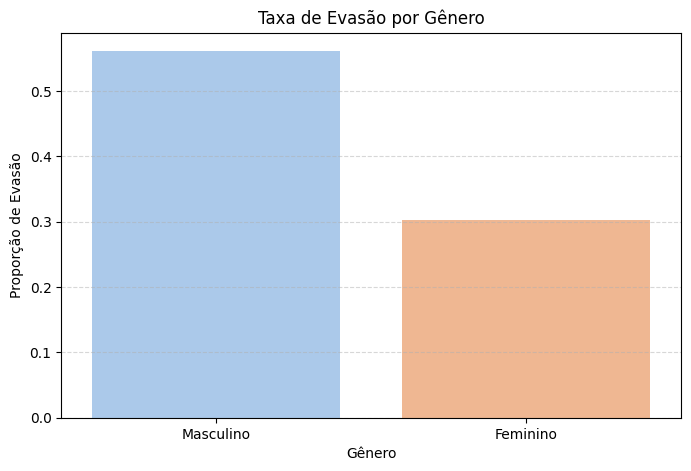

In [88]:
# Relação entre Gênero e Evasão
plt.figure(figsize=(8, 5))
sns.barplot(data=df_analise, x='Genero', y='evasao', palette='pastel', errorbar=None)
plt.title('Taxa de Evasão por Gênero')
plt.ylabel('Proporção de Evasão')
plt.xlabel('Gênero')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

/tmp/ipykernel_497/227120917.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=taxa_evasao_curso, y='Curso', x='evasao', palette='viridis')


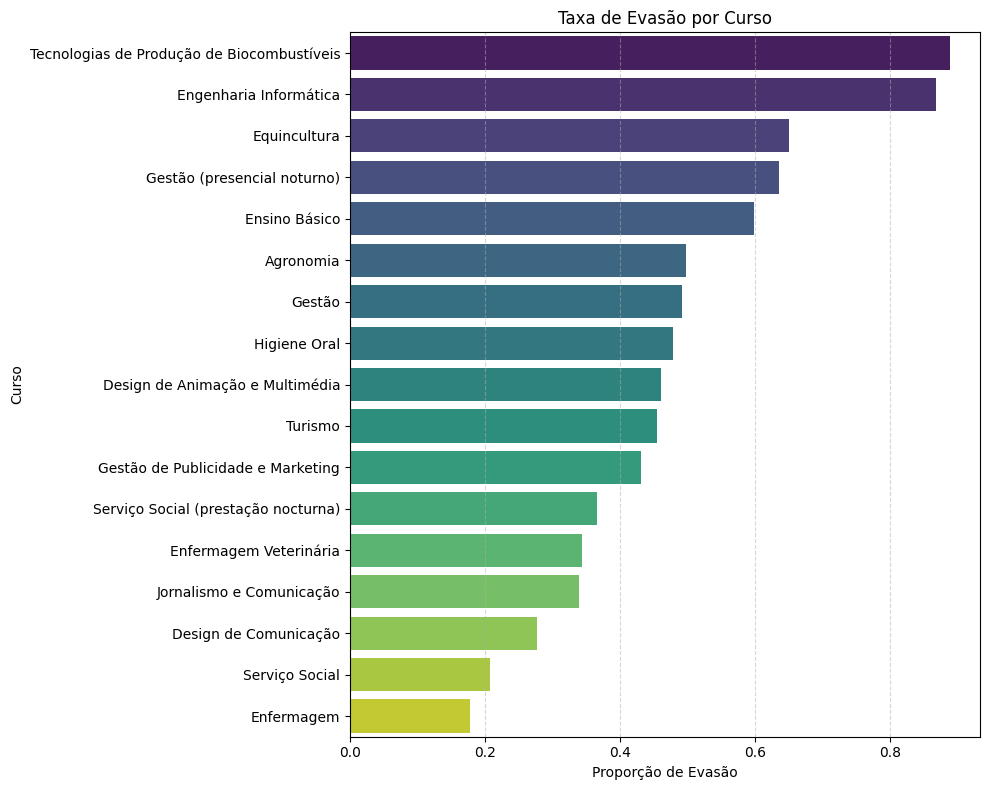

In [89]:
# Taxa de Evasão por Curso
taxa_evasao_curso = df_analise.groupby('Curso')['evasao'].mean().sort_values(ascending=False).reset_index()

plt.figure(figsize=(10, 8))
sns.barplot(data=taxa_evasao_curso, y='Curso', x='evasao', palette='viridis')
plt.title('Taxa de Evasão por Curso')
plt.xlabel('Proporção de Evasão')
plt.ylabel('Curso')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

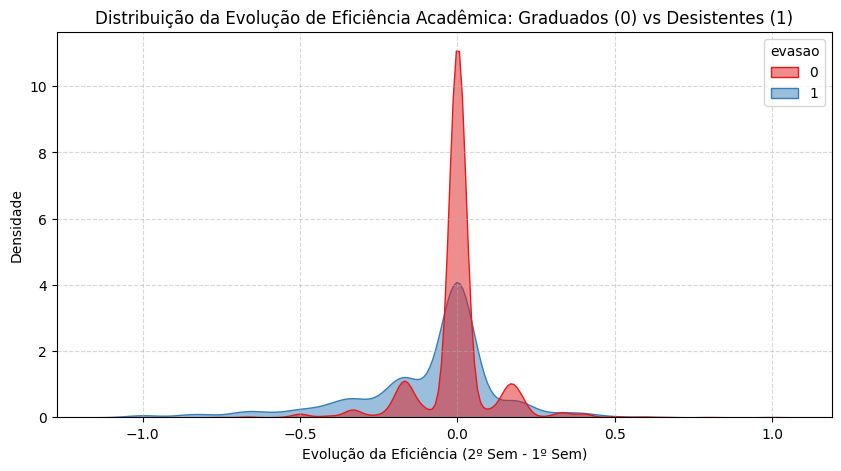

In [90]:
# Distribuição da Evolução de Eficiência por Evasão
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df_analise, x='Evolucao_Eficiencia', hue='evasao', fill=True, common_norm=False, palette='Set1', alpha=0.5)
plt.title('Distribuição da Evolução de Eficiência Acadêmica: Graduados (0) vs Desistentes (1)')
plt.xlabel('Evolução da Eficiência (2º Sem - 1º Sem)')
plt.ylabel('Densidade')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [91]:
(df_modelo["UnidadesCurriculares2SemestreInscrito"] == 0).sum()

np.int64(152)

In [92]:
(df_modelo["UnidadesCurriculares1SemestreInscrito"] == 0).sum()

np.int64(152)

In [93]:
c1 = "UnidadesCurriculares1SemestreInscrito"
c2 = "UnidadesCurriculares2SemestreInscrito"

nunca = (df_modelo[c1] == 0) & (df_modelo[c2] == 0)
nunca.sum()                              # esperado: 152 se forem os mesmos
(df_modelo[c1] == 0).sum()               # 152
pd.crosstab(nunca, df_modelo["evasao"], margins=True)
df_modelo.loc[nunca, "evasao"].mean()    # taxa de evasão do grupo

np.float64(0.506578947368421)

In [94]:
cols = ["UnidadesCurriculares1SemestreCreditado", "UnidadesCurriculares2SemestreCreditado",
        "UnidadesCurriculares1SemestreAprovado", "UnidadesCurriculares2SemestreAprovado",
        "UnidadesCurriculares1SemestreAvaliacoes", "UnidadesCurriculares2SemestreAvaliacoes"]

grupo = df_modelo[nunca]
grupo[cols].describe().T
grupo.groupby("evasao")[cols].mean().T

evasao,0,1
UnidadesCurriculares1SemestreCreditado,0.0,0.0
UnidadesCurriculares2SemestreCreditado,0.0,0.0
UnidadesCurriculares1SemestreAprovado,0.0,0.0
UnidadesCurriculares2SemestreAprovado,0.0,0.0
UnidadesCurriculares1SemestreAvaliacoes,0.0,0.0
UnidadesCurriculares2SemestreAvaliacoes,0.0,0.0


In [95]:
grupo[["UnidadesCurriculares1SemestreGrau","UnidadesCurriculares2SemestreGrau"]].describe().T

,count,unique,top,freq
UnidadesCurriculares1SemestreGrau,152,1,0,152
UnidadesCurriculares2SemestreGrau,152,1,0,152


### Limpeza do DF

In [96]:
c1 = "UnidadesCurriculares1SemestreInscrito"
c2 = "UnidadesCurriculares2SemestreInscrito"

nunca = (df_modelo[c1] == 0) & (df_modelo[c2] == 0)

df_limpo = df_modelo[~nunca].copy().reset_index(drop=True)

print(df_modelo.shape, "->", df_limpo.shape)
print(df_limpo["evasao"].value_counts(normalize=True))

(3630, 28) -> (3478, 28)
evasao
0    0.613571
1    0.386429
Name: proportion, dtype: float64


In [97]:
(df_limpo[c1] == 0).sum(), (df_limpo[c2] == 0).sum()   # devem ser 0 no sem. 1; confira o sem. 2
df_limpo.isna().sum().sum()

np.int64(0)

In [98]:
(df_limpo[c2] == 0).sum(), (df_limpo[c1] == 0).sum()   # devem ser 0 no sem. 1; confira o sem. 2
df_limpo.isna().sum().sum()

np.int64(0)

## Tratamento de Outliers e Imputação Preventiva para Produção
Para evitar a perda de registros sensíveis de alunos, vamos construir um transformador personalizado do scikit-learn (`OutlierClipper`) que realiza a técnica de *Winsorização* (limita valores extremos usando os limites inferior e superior do IQR calculados estritamente na base de treino).

In [99]:
class OutlierClipper(BaseEstimator, TransformerMixin):
    """
    Transformador personalizado para limitar outliers (Winsorização)
    baseado no limite de 1.5 * IQR.
    """
    def __init__(self, factor=1.5):
        self.factor = factor
        self.lower_bounds_ = {}
        self.upper_bounds_ = {}

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        for col in X_df.columns:
            # Ignora colunas binárias já codificadas (0 ou 1)
            if X_df[col].nunique() > 2:
                q25 = X_df[col].quantile(0.25)
                q75 = X_df[col].quantile(0.75)
                iqr = q75 - q25
                self.lower_bounds_[col] = q25 - self.factor * iqr
                self.upper_bounds_[col] = q75 + self.factor * iqr
            else:
                self.lower_bounds_[col] = -np.inf
                self.upper_bounds_[col] = np.inf
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        for col in X_df.columns:
            X_df[col] = np.clip(X_df[col], self.lower_bounds_[col], self.upper_bounds_[col])
        return X_df.values

## Validação do Tratamento de Outliers (Antes vs. Depois)
Para confirmar que o `OutlierClipper` limitou corretamente os extremos, vamos analisar uma variável com alta amplitude (como `UnidadesCurriculares1SemestreAvaliacoes`) comparando seus valores originais de treino com os valores após passarem pelo pipeline (revertendo a escala apenas para fins de visualização).

In [100]:
# índice da coluna de avaliações no output do processador
# Como o ColumnTransformer coloca as colunas numéricas primeiro, mapeia a ordem delas:
col_alvo = 'UnidadesCurriculares1SemestreAvaliacoes'
idx_col = num_cols.index(col_alvo)

# Extrai os dados originais e os dados transformados para essa coluna
valores_originais = X_train[col_alvo].values

# Para visualizar sem a escala padrão (Z-score), recupera os valores clipados revertendo o StandardScaler
# valor_clipado = (valor_padronizado * desvio_padrao) + media
mean_scaler = preprocessor.named_transformers_['num'].named_steps['scaler'].mean_[idx_col]
scale_scaler = preprocessor.named_transformers_['num'].named_steps['scaler'].scale_[idx_col]

valores_transformados_padronizados = X_train_processed[:, idx_col]
valores_transformados_finais = (valores_transformados_padronizados * scale_scaler) + mean_scaler

# 3. Exibe a comparação de limites máximos e mínimos
print(f"=== Variável: {col_alvo} ===")
print(f"Antes do Pipeline (Original): Min = {valores_originais.min()} | Max = {valores_originais.max()}")
print(f"Após o Pipeline (Clipado):     Min = {valores_transformados_finais.min():.2f} | Max = {valores_transformados_finais.max():.2f}")

# 4. Mostra o limite máximo calculado pelo OutlierClipper para esta coluna
clipper_step = preprocessor.named_transformers_['num'].named_steps['clipper']
print(f"Limite superior calculado (IQR * 1.5): {clipper_step.upper_bounds_[idx_col]:.2f}")

=== Variável: UnidadesCurriculares1SemestreAvaliacoes ===
Antes do Pipeline (Original): Min = 0 | Max = 45
Após o Pipeline (Clipado):     Min = 0.00 | Max = 16.00
Limite superior calculado (IQR * 1.5): 16.00


## Visualização da Distribuição das Variáveis (Antes vs. Depois do Pipeline)
Vamos plotar a distribuição de algumas variáveis numéricas chaves para ver o efeito visual da remoção de outliers (`OutlierClipper`) e da padronização (`StandardScaler`).

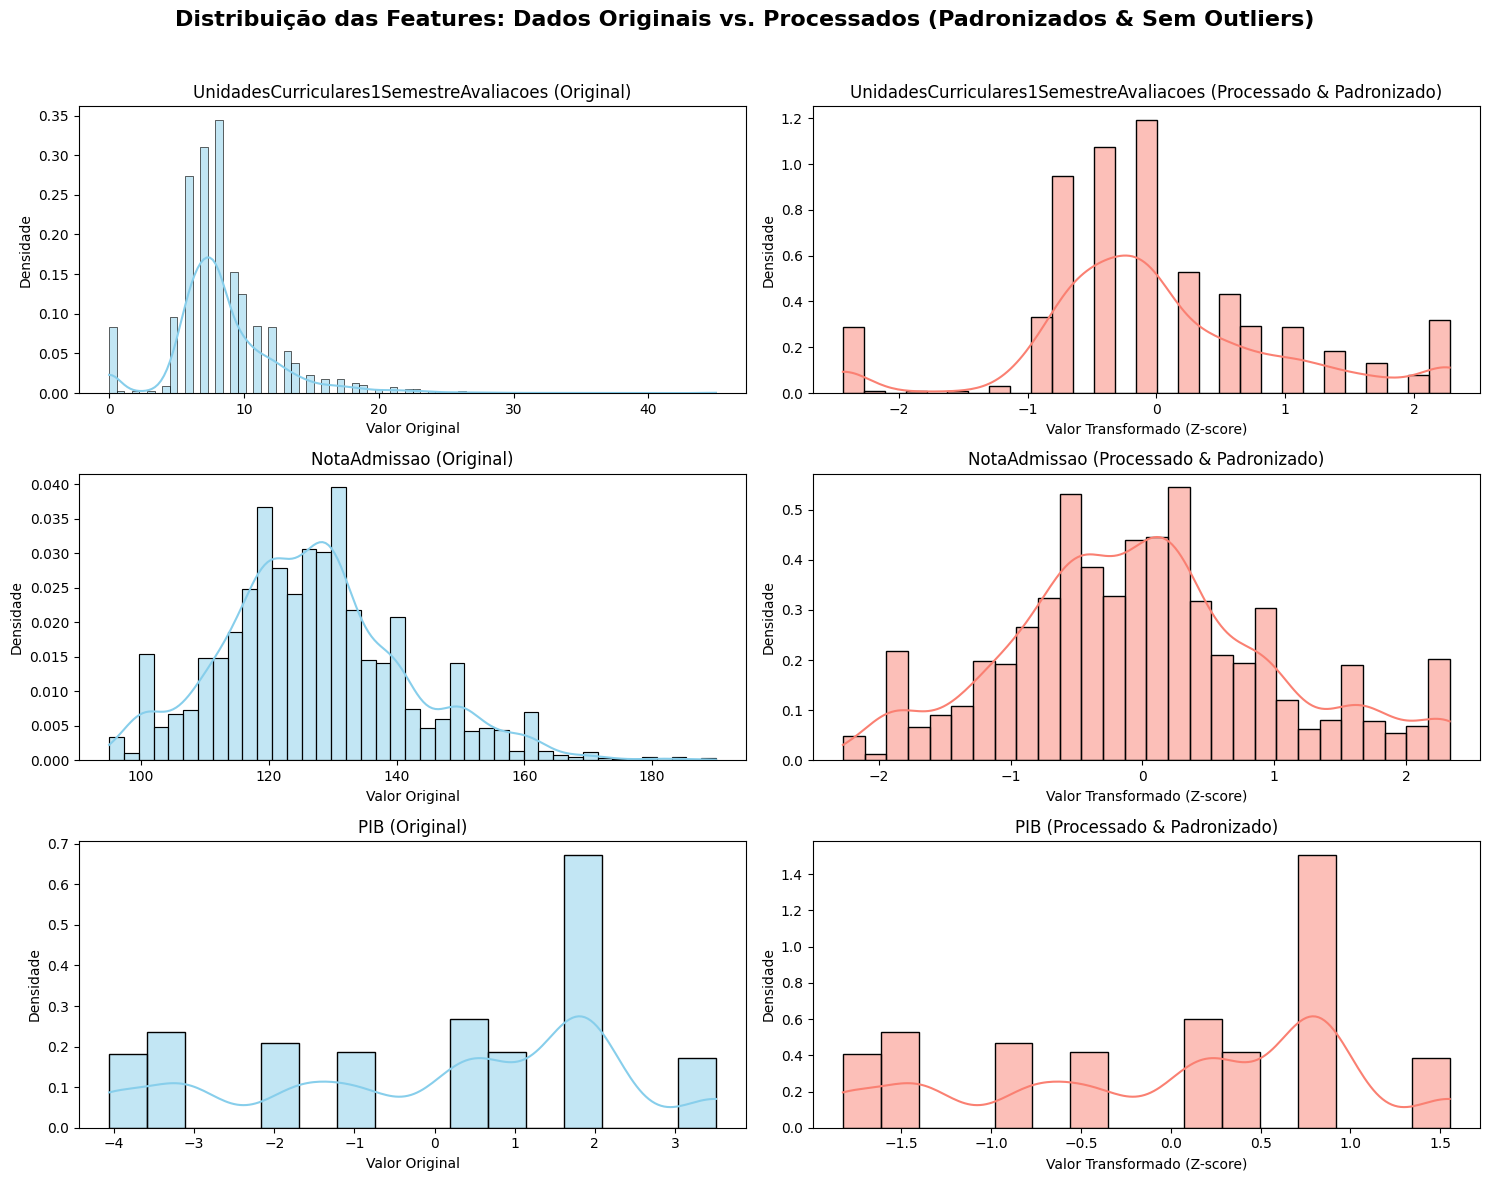

In [101]:
# Variáveis selecionadas para avaliar a distribuição
features_para_plot = ['UnidadesCurriculares1SemestreAvaliacoes', 'NotaAdmissao', 'PIB']

fig, axes = plt.subplots(len(features_para_plot), 2, figsize=(15, 12))
fig.suptitle('Distribuição das Features: Dados Originais vs. Processados (Padronizados & Sem Outliers)', fontsize=16, fontweight='bold')

for i, col in enumerate(features_para_plot):
    idx_col = num_cols.index(col)

    # Plot Original (Antes)
    sns.histplot(X_train[col], ax=axes[i, 0], kde=True, color='skyblue', stat='density')
    axes[i, 0].set_title(f'{col} (Original)', fontsize=12)
    axes[i, 0].set_xlabel('Valor Original')
    axes[i, 0].set_ylabel('Densidade')

    # Plot Processado (Depois)
    sns.histplot(X_train_processed[:, idx_col], ax=axes[i, 1], kde=True, color='salmon', stat='density')
    axes[i, 1].set_title(f'{col} (Processado & Padronizado)', fontsize=12)
    axes[i, 1].set_xlabel('Valor Transformado (Z-score)')
    axes[i, 1].set_ylabel('Densidade')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## Divisão de Treino/Teste e Mapeamento de Colunas
Vamos isolar nossa variável resposta (`evasao`) e categorizar nossas colunas numéricas e categóricas para o pré-processamento

In [102]:
# Define as features (X) e o target (y)
X = df_limpo.drop(columns=['evasao'])
y = df_limpo['evasao']

# 2. Divide os dados de forma estratificada (mantendo a proporção de evasão de ~38% em ambas as bases)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Força a conversão de colunas numéricas que ainda possam estar salvas como string/object
colunas_converter = [
    'NotaAdmissao', 'UnidadesCurriculares1SemestreGrau',
    'UnidadesCurriculares2SemestreGrau', 'TaxaDesemprego',
    'TaxaInflacao', 'PIB'
]

for col in colunas_converter:
    if col in X_train.columns:
        X_train[col] = X_train[col].astype(str).str.replace(',', '.').astype(float)
        X_test[col] = X_test[col].astype(str).str.replace(',', '.').astype(float)

# Separa colunas por tipo para processamento independente
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Quantidade de features numéricas: {len(num_cols)}")
print(f"Quantidade de features categóricas: {len(cat_cols)}")

Quantidade de features numéricas: 21
Quantidade de features categóricas: 6


## Construção e Execução do Pipeline do scikit-learn
Vamos montar o `ColumnTransformer` usando os pipelines preventivos com imputação pela mediana/moda, remoção de outliers e padronização, e depois rodar nos dados de treino

In [103]:
# Pipeline Numérico: Imputa nulos na mediana (preventivo) -> Clip de outliers -> Normalização standard
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('clipper', OutlierClipper(factor=1.5)),
    ('scaler', StandardScaler())
])

# Pipeline Categórico: Imputa nulos na moda (preventivo) -> One-Hot-Encoder robusto a novas categorias
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Unindo os pipelines no ColumnTransformer por tipo de coluna
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# Ajustando o pré-processador aos dados de treino e aplicando a transformação
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processamento concluído com sucesso!")
print("Formato dos dados originais de treino:", X_train.shape)
print("Formato dos dados de treino após o Pipeline (com One-Hot-Encoding):", X_train_processed.shape)

Processamento concluído com sucesso!
Formato dos dados originais de treino: (2782, 27)
Formato dos dados de treino após o Pipeline (com One-Hot-Encoding): (2782, 174)


## Inspeção Estrutural das Variáveis Pós-Pipeline
Vamos validar as features geradas pelo `ColumnTransformer` para entender como o OneHotEncoder expandiu nossas variáveis categóricas para produção

In [104]:
# Recuperando os nomes das novas colunas categóricas geradas pelo OneHotEncoder
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
novas_cols_categoricas = cat_encoder.get_feature_names_out(cat_cols).tolist()

# Lista total de colunas na ordem que o ColumnTransformer organiza (numéricas primeiro, depois categóricas)
features_finais_nomes = num_cols + novas_cols_categoricas

print("=== ESTRUTURA FINAL DOS DADOS PARA O MODELO ===\n")
print(f"Total de features numéricas originais (mantidas): {len(num_cols)}")
print(f"Total de novas colunas categóricas geradas: {len(novas_cols_categoricas)}")
print(f"Total geral de colunas de entrada para os modelos: {len(features_finais_nomes)}")

print("\n--- Primeiras 10 colunas categóricas expandidas no OneHotEncoder ---")
for col_nome in novas_cols_categoricas[:10]:
    print(f" - {col_nome}")

=== ESTRUTURA FINAL DOS DADOS PARA O MODELO ===

Total de features numéricas originais (mantidas): 21
Total de novas colunas categóricas geradas: 153
Total geral de colunas de entrada para os modelos: 174

--- Primeiras 10 colunas categóricas expandidas no OneHotEncoder ---
 - EstadoCivil_Casado
 - EstadoCivil_Divorciado
 - EstadoCivil_Separado Judicialmente
 - EstadoCivil_Solteiro
 - EstadoCivil_União de Fato
 - EstadoCivil_Viúvo
 - Curso_Agronomia
 - Curso_Design de Animação e Multimédia
 - Curso_Design de Comunicação
 - Curso_Enfermagem


## Treinamento do Modelo com Validação Cruzada Estratificada
Vamos criar um pipeline integrado contendo o pré-processamento e um modelo classificador `RandomForestClassifier`. Em seguida, avaliaremos o comportamento preditivo por meio de Validação Cruzada de 5 partições (Folds).

In [105]:
# 1. Definindo o Pipeline final unificado (Pré-processamento + Classificador)
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced', n_jobs=-1))
])

# 2. Configurando a validação cruzada estratificada (5 folds)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Definindo as métricas para avaliação multi-score
scoring_metrics = ['accuracy', 'f1', 'roc_auc']

# 4. Executando a validação cruzada nos dados de treino originais (o pipeline cuida do fit_transform em cada fold de forma isolada!)
cv_results = cross_validate(
    model_pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring=scoring_metrics,
    return_train_score=False,
    n_jobs=-1
)

# 5. Exibindo os resultados médios de performance
print("=== RESULTADOS DA VALIDAÇÃO CRUZADA (5 FOLDS) ===\n")
print(f"Acurácia Média: {cv_results['test_accuracy'].mean():.4f} (+/- {cv_results['test_accuracy'].std():.4f})")
print(f"F1-Score Médio: {cv_results['test_f1'].mean():.4f} (+/- {cv_results['test_f1'].std():.4f})")
print(f"ROC AUC Média:  {cv_results['test_roc_auc'].mean():.4f} (+/- {cv_results['test_roc_auc'].std():.4f})")

=== RESULTADOS DA VALIDAÇÃO CRUZADA (5 FOLDS) ===

Acurácia Média: 0.9195 (+/- 0.0141)
F1-Score Médio: 0.8881 (+/- 0.0212)
ROC AUC Média:  0.9529 (+/- 0.0147)


```markdown
## Avaliação Final no Conjunto de Teste (Dados Inéditos)
Como os resultados da validação cruzada foram excelentes, vamos treinar o pipeline completo em todos os dados de treino e avaliá-lo no conjunto de teste independente que separamos no início (`X_test` e `y_test`). Isso nos dará o veredito final da performance antes de salvar o modelo para produção.
```

=== RELATÓRIO DE CLASSIFICAÇÃO (BASE DE TESTE) ===

              precision    recall  f1-score   support

    Graduado       0.90      0.96      0.93       427
  Desistente       0.94      0.84      0.88       269

    accuracy                           0.92       696
   macro avg       0.92      0.90      0.91       696
weighted avg       0.92      0.92      0.91       696



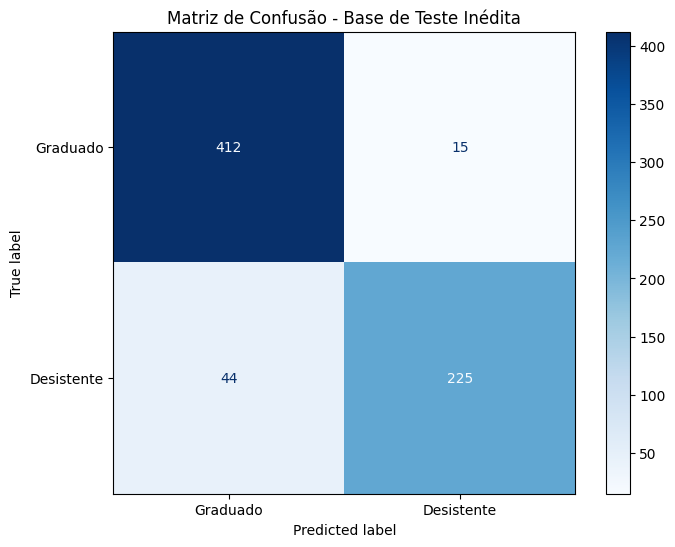

In [106]:
# Treinando o pipeline completo com toda a base de treino
model_pipeline.fit(X_train, y_train)

# predições na base de teste
y_pred = model_pipeline.predict(X_test)
y_pred_proba = model_pipeline.predict_proba(X_test)[:, 1]

# relatório de classificação detalhado
print("=== RELATÓRIO DE CLASSIFICAÇÃO (BASE DE TESTE) ===\n")
print(classification_report(y_test, y_pred, target_names=['Graduado', 'Desistente']))

# 4. Plotando a Matriz de Confusão para entender os erros e acertos do modelo
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Graduado', 'Desistente'])
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Matriz de Confusão - Base de Teste Inédita')
plt.grid(False)
plt.show()

## Diagnóstico de Overfitting e Underfitting

Com base nos resultados das etapas de validação e teste:

### O Modelo não possue Overfitting (Sobreajuste)
O overfitting é caracterizado por um cenário onde o modelo apresenta uma excelente performance nos dados de treino/validação, mas decai drasticamente ao ser exposto a dados novos e inéditos (teste).

* **Evidência nos Dados:**
  * **Validação Cruzada (Média dos 5 folds):** Acurácia de **91.95%** e F1-Score de **88.81%**.
  * **Base de Teste (Inédita):** Acurácia de **92.00%** e F1-Score para a classe *Desistente* de **88.00%**.
* **Veredito:** Como a diferença de performance entre a validação cruzada simulada e o conjunto de teste real é praticamente nula (diferença inferior a 1%), o modelo demonstra uma capacidade de **generalização excelente** e está livre de overfitting.

### O Modelo não possue Underfitting (Subajuste)
O underfitting ocorre quando o modelo é simples demais ou os atributos não são explicativos o suficiente, impedindo-o de aprender os padrões dos dados, resultando em métricas baixas e insatisfatórias em ambas as bases.

* **Evidência nos Dados:**
  * O modelo atingiu **92.00% de Acurácia Geral** e uma área sob a curva ROC (**ROC AUC de 95.29%**).
  * O **F1-Score de 88.00%** na classe minoritária (*Desistente*) comprova que o modelo consegue prever o evento de interesse com alta precisão e sensibilidade simultaneamente.
* **Veredito:** O modelo conseguiu capturar com sucesso as relações complexas e não-lineares do dataset (como o impacto das reprovações, notas e fatores econômicos de mensalidades), descartando qualquer hipótese de underfitting.

### Análise do Equilíbrio (Precisão vs. Recall na Classe Alvo)
Ao inspecionar a **Matriz de Confusão** e o **Relatório de Classificação** na base de teste, observei as seguintes forças práticas para o negócio:

* **Precisão de 94% para Desistentes:** Significa que quando o modelo sinaliza que um aluno vai evadir, ele está correto em **94% dos casos** (gerando pouquíssimos falsos alarmes — apenas 15 alunos na base de teste). Isso evita que a instituição gaste recursos em ações de retenção desnecessárias com quem não precisa.
* **Recall de 84% para Desistentes:** O modelo consegue identificar proativamente **84% de todos os alunos que realmente vão evadir** (deixando passar apenas 44 alunos como falso negativo).

**Conclusão:** O modelo está altamente balanceado, estável e pronto para ser integrado a um ambiente de produção ou painel analítico (Streamlit) para tomada de decisão em tempo real.


In [107]:
# Salvando o pipeline final do modelo treinado
joblib.dump(model_pipeline, 'modelo_evasao_final.joblib')
print("✔ Modelo completo (pipeline) salvo com sucesso como 'modelo_evasao_final.joblib'")

# Unindo as features e a classe alvo de treino para salvar em um único arquivo
df_treino_salvar = X_train.copy()
df_treino_salvar['evasao'] = y_train
df_treino_salvar.to_csv('dados_treino.csv', index=False, encoding='utf-8')
print("✔ Dados de Treino salvos com sucesso como 'dados_treino.csv'")

# Unindo as features e a classe alvo de teste para salvar em um único arquivo
df_teste_salvar = X_test.copy()
df_teste_salvar['evasao'] = y_test
df_teste_salvar.to_csv('dados_teste.csv', index=False, encoding='utf-8')
print("✔ Dados de Teste salvos com sucesso como 'dados_teste.csv'")


✔ Modelo completo (pipeline) salvo com sucesso como 'modelo_evasao_final.joblib'
✔ Dados de Treino salvos com sucesso como 'dados_treino.csv'
✔ Dados de Teste salvos com sucesso como 'dados_teste.csv'
